# Windy Gridworld (Sutton & Barto, Example 6.5)

A 10x7 gridworld with a crosswind running upward through the middle of the grid.

- **Grid:** 10 columns x 7 rows.
- **Start:** column 0, row 3 (middle row, leftmost column).
- **Goal:** column 7, row 3.
- **Actions:** 4-way movement (up, down, left, right). An action that would move the agent off the grid instead leaves it as close to the edge as the move allows (clipped, not cancelled -- see below).
- **Reward:** -1 per step, undiscounted ($\gamma=1$), episodic -- the episode ends the moment the agent reaches the goal.
- **Wind:** in each column, a crosswind pushes the agent upward by a fixed number of extra cells on every move through that column:

| column | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| wind | 0 | 0 | 0 | 1 | 1 | 1 | 2 | 2 | 1 | 0 |

This notebook implements just the environment first; Sarsa, Q-learning, Double Q-learning, and Expected Sarsa are added afterward, one at a time.

## Behavior policy vs. target policy, at a glance

Each algorithm below has two policies in play: the **behavior policy** (what `select_action` actually does -- the policy generating the agent's real actions in the environment) and the **target policy** (the policy implicitly being evaluated by the TD target computed inside `update`). When these two match, the algorithm is on-policy; when they differ, it's off-policy.

| Algorithm | `select_action` (behavior) | implicit policy inside `update` (target) | on/off-policy |
|---|---|---|---|
| Sarsa | $\varepsilon$-greedy w.r.t. $Q$ | $\varepsilon$-greedy w.r.t. $Q$ (the *same* `next_action` that was actually sampled) | on-policy |
| Expected Sarsa (as implemented here) | $\varepsilon$-greedy w.r.t. $Q$ | $\varepsilon$-greedy w.r.t. $Q$ (same $\varepsilon$, via an exact expectation instead of a sample) | on-policy |
| Q-learning | $\varepsilon$-greedy w.r.t. $Q$ | **greedy** w.r.t. $Q$ (via `max`) | off-policy |
| Double Q-learning | $\varepsilon$-greedy w.r.t. $Q_1 + Q_2$ | **greedy** w.r.t. whichever table isn't being updated this step | off-policy |

Q-learning and Double Q-learning are implemented further down; this table is here as an upfront reference for the nuance that distinguishes all four.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [41]:
def adjustAxeProperties(ax_obj, x_fontsize, x_rotation, y_fontsize, y_rotation):
    for tick in ax_obj.xaxis.get_major_ticks():
        tick.label1.set_fontsize(x_fontsize)
        tick.label1.set_rotation(x_rotation)
    for tick in ax_obj.yaxis.get_major_ticks():
        tick.label1.set_fontsize(y_fontsize)
        tick.label1.set_rotation(y_rotation)

In [79]:
def plot_learning_curves(steps_per_episode_by_label, title="Windy Gridworld"):
    """steps_per_episode_by_label: dict mapping a label (e.g. an algorithm
    name) to a steps-per-episode array, as returned by train(). Plots
    cumulative time steps (x) vs. episodes completed (y) for each entry,
    overlaid on one set of axes -- reproduces the book's Figure 6.3 style
    and generalizes directly to comparing multiple algorithms."""
    fontsize = 12
    fig, ax = plt.subplots(figsize=(6, 6))
    for label, steps_per_episode in steps_per_episode_by_label.items():
        cumulative_steps = np.cumsum(steps_per_episode)
        ax.plot(cumulative_steps, np.arange(1, len(steps_per_episode) + 1), label=label)
    ax.set_xlabel("Time steps", fontsize=fontsize, labelpad=10)
    ax.set_ylabel("Episodes", fontsize=fontsize, labelpad=10)
    adjustAxeProperties(ax, fontsize, 20, fontsize, 0)
    ax.set_title(title, fontsize=fontsize)
    ax.legend(loc="best", fontsize=fontsize)
    plt.show()

## Environment setup

States are `(row, col)` pairs, 0-indexed, with `row` increasing *downward* (row 0 is the top row of the grid -- the usual array/display convention). "Up" therefore means `row - 1`.

Actions are encoded as `(row_delta, col_delta)` pairs.

In [80]:
GRID_HEIGHT = 7
GRID_WIDTH = 10

WIND = [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]

START = (3, 0)
GOAL = (3, 7)

ACTION_UP = 0
ACTION_DOWN = 1
ACTION_LEFT = 2
ACTION_RIGHT = 3
ACTIONS = [ACTION_UP, ACTION_DOWN, ACTION_LEFT, ACTION_RIGHT]

ACTION_DELTAS = {
    ACTION_UP: (-1, 0),
    ACTION_DOWN: (1, 0),
    ACTION_LEFT: (0, -1),
    ACTION_RIGHT: (0, 1),
}

## Dynamics

Given a state and an action, `step` computes the next state and reward. The action's intended move and the current column's wind both act on `row`; the combined result is *clipped* to the grid (not cancelled) if it would land out of bounds. Wind uses the column the agent is in **before** the move (horizontal actions don't retroactively change which column's wind applies). Reward is -1 for every step; the episode ends the instant the agent reaches `GOAL`.

In [81]:
def step(state, action):
    row, col = state
    row_delta, col_delta = ACTION_DELTAS[action]

    next_row = row + row_delta - WIND[col]
    next_col = col + col_delta

    next_row = min(max(next_row, 0), GRID_HEIGHT - 1)
    next_col = min(max(next_col, 0), GRID_WIDTH - 1)

    next_state = (next_row, next_col)
    reward = -1.0
    done = next_state == GOAL
    return next_state, reward, done

In [82]:
GOAL 

(3, 7)

In [83]:
# Quick sanity check

# Per the book: one cell to the right of the goal, moving left lands just
# above the goal.
next_state, reward, done = step((GOAL[0], GOAL[1] + 1), ACTION_LEFT)
assert next_state == (GOAL[0] - 1, GOAL[1])
assert reward == -1.0
assert not done

# Wind can carry the agent straight into the goal.
next_state, reward, done = step((4, 8), ACTION_LEFT)
assert next_state == GOAL
assert done

# Edge clipping: moving off the top of the grid leaves the agent at row 0.
next_state, reward, done = step((0, 0), ACTION_UP)
assert next_state == (0, 0)

# Edge clipping: moving off the left of the grid leaves the agent at col 0.
next_state, reward, done = step((3, 0), ACTION_LEFT)
assert next_state == (3, 0)

print("all sanity checks passed")

all sanity checks passed


## Agent interface and shared training driver

Sarsa, Expected Sarsa, Q-learning, and Double Q-learning all share the same outer shape -- step through an episode, pick actions $\varepsilon$-greedily, update an action-value estimate -- and only differ in exactly how the TD target is computed. So every algorithm below is implemented as a small subclass of `TDAgent`, sharing one `select_action`/`update` interface, and the episode loop (`run_episode`) and training loop (`train`) are written once and reused for all four -- the driver never needs to know which algorithm it's running.

One subtlety: Sarsa's target is genuinely **on-policy** -- it must use the *exact* action the agent is about to take next, not a fresh independent sample (otherwise it would silently stop being Sarsa). Q-learning, Expected Sarsa, and Double Q-learning are **off-policy** in the sense that their targets bootstrap off `Q[next_state]` directly (via max / expectation / cross-table lookup) and don't depend on which action actually gets taken next. `run_episode` below selects `next_action` once per step and always passes it to `update`; on-policy agents use it, off-policy agents just ignore it. `TDAgent.USES_NEXT_ACTION` documents which category a given subclass falls into -- it's not branched on anywhere, it's purely there so the class declaration tells you at a glance.

In [84]:
def epsilon_greedy(q_values, epsilon):
    """q_values: array of action-values for one state, indexed like ACTIONS.
    Returns an action, epsilon-greedy with respect to q_values. Ties for the
    greedy action are broken uniformly at random (not just "first index"),
    so the agent doesn't develop a systematic bias toward a particular
    action whenever several look equally good."""
    if np.random.rand() < epsilon:
        return np.random.choice(ACTIONS)
    best = np.flatnonzero(q_values == q_values.max())
    return np.random.choice(best)

In [85]:
class TDAgent:
    """Shared interface for all TD control algorithms used on the Windy
    Gridworld. Subclasses implement select_action and update; the episode
    loop and training loop (below) are shared and never need to know which
    concrete algorithm they're driving."""

    USES_NEXT_ACTION = False  # True only for genuinely on-policy targets (Sarsa)

    def select_action(self, state):
        raise NotImplementedError

    def update(self, state, action, reward, next_state, next_action, done):
        """next_action is the action the agent will actually take next.
        On-policy agents (Sarsa) use it in their target; off-policy agents
        (Expected Sarsa, Q-learning, Double Q-learning) ignore it and
        bootstrap off next_state's action-values directly."""
        raise NotImplementedError

In [86]:
def run_episode(agent, max_steps=10_000):
    """Run one episode starting from START, letting `agent` choose actions
    and update itself after every step. Returns the number of steps taken
    (== the episode length used for the book's step-count comparisons)."""
    state = START
    action = agent.select_action(state)
    steps = 0
    while True:
        next_state, reward, done = step(state, action)
        steps += 1
        next_action = None if done else agent.select_action(next_state)
        agent.update(state, action, reward, next_state, next_action, done)
        if done or steps >= max_steps:
            break
        state, action = next_state, next_action
    return steps


def train(agent, num_episodes):
    """Train `agent` for num_episodes episodes, returning the number of
    steps taken in each one."""
    steps_per_episode = np.zeros(num_episodes, dtype=int)
    for ep in range(num_episodes):
        steps_per_episode[ep] = run_episode(agent)
    return steps_per_episode

### Sanity check: a scripted agent

Before implementing any real learning algorithm, check that `run_episode`/`train` work correctly in isolation, using an agent that just follows a fixed, pre-computed action sequence (the optimal 15-step path found earlier via BFS) and does no learning at all. If the driver is correct, this agent should reach the goal in exactly 15 steps.

In [87]:
# Quick sanity check
class ScriptedAgent(TDAgent):
    """Follows a fixed action sequence; does no learning. Used only to
    validate run_episode/train in isolation from any real algorithm."""

    def __init__(self, actions):
        self.actions = actions
        self.t = 0

    def select_action(self, state):
        a = self.actions[self.t]
        self.t += 1
        return a

    def update(self, state, action, reward, next_state, next_action, done):
        pass  # no learning


# The optimal 15-step path found via BFS earlier: 9x RIGHT, 4x DOWN, 2x LEFT.
optimal_path = [ACTION_RIGHT] * 9 + [ACTION_DOWN] * 4 + [ACTION_LEFT] * 2

agent = ScriptedAgent(optimal_path)
steps = run_episode(agent)
assert steps == 15, steps
print(f"scripted agent reached the goal in {steps} steps, as expected")

scripted agent reached the goal in 15 steps, as expected


## Sarsa

On-policy TD control (the name comes from the quintuple it uses: **S**tate, **A**ction, **R**eward, **S**tate, **A**ction). The target uses $Q(S', A')$ where $A'$ is the *actual* action the agent is about to take next:

$$Q(S, A) \leftarrow Q(S, A) + \alpha \big[ R + \gamma\, Q(S', A') - Q(S, A) \big]$$

If the episode ends on this step, there's no $S'$ to bootstrap from, so the target is just $R$.

In [88]:
class SarsaAgent(TDAgent):
    USES_NEXT_ACTION = True

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))

    def select_action(self, state):
        row, col = state
        return epsilon_greedy(self.Q[row, col], self.epsilon)

    def update(self, state, action, reward, next_state, next_action, done):
        row, col = state
        current = self.Q[row, col, action]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            target = reward + self.gamma * self.Q[next_row, next_col, next_action]
        self.Q[row, col, action] = current + self.alpha * (target - current)

first 10 episodes: [251 783 243 218 117  93 149  80 125  48]
last 10 episodes:  [17 37 19 21 24 28 21 22 27 15]
mean steps over last 20 episodes: 21.9 (optimal is 15)


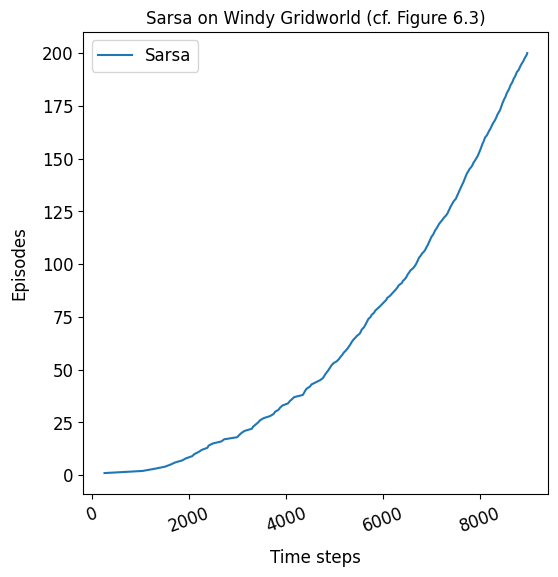

In [89]:
# Quick sanity check
np.random.seed(0)
sarsa_agent = SarsaAgent(alpha=0.5, epsilon=0.1)
sarsa_steps = train(sarsa_agent, num_episodes=200)

print("first 10 episodes:", sarsa_steps[:10])
print("last 10 episodes: ", sarsa_steps[-10:])

# Learning should have made episodes much shorter than the early, mostly
# random-exploration episodes.
assert sarsa_steps[-20:].mean() < sarsa_steps[:20].mean()

# After 200 episodes it should be close to the optimal 15 steps (some slack
# for ongoing epsilon-greedy exploration).
assert sarsa_steps[-20:].mean() < 30
print(f"mean steps over last 20 episodes: {sarsa_steps[-20:].mean():.1f} (optimal is 15)")

plot_learning_curves({"Sarsa": sarsa_steps}, title="Sarsa on Windy Gridworld (cf. Figure 6.3)")

The book's Figure 6.3 plots cumulative time steps on the x-axis against the number of episodes completed so far -- as Sarsa learns, episodes get shorter, so the slope (episodes per time step) increases. `plot_learning_curves` below takes a dict of `{label: steps_per_episode}` and overlays one such curve per entry -- written generally now so the exact same function produces both this single-algorithm check and the four-way comparison at the end.

## Expected Sarsa

Like Sarsa, but instead of bootstrapping off the one action that happens to get sampled next, it bootstraps off the *expected* value of $Q(S', \cdot)$ under the $\varepsilon$-greedy policy itself -- replacing a single noisy sample with its exact expectation:

$$Q(S, A) \leftarrow Q(S, A) + \alpha \Big[ R + \gamma \sum_a \pi(a \mid S')\, Q(S', a) - Q(S, A) \Big]$$

where $\pi$ is $\varepsilon$-greedy with respect to $Q(S', \cdot)$: each of the (possibly tied) greedy actions gets $\frac{\varepsilon}{|A|} + \frac{1-\varepsilon}{|A^*|}$, every other action gets $\frac{\varepsilon}{|A|}$ ($A^*$ = the set of tied-greedy actions). Since this target doesn't depend on which action actually gets taken next, Expected Sarsa's `update` ignores `next_action` entirely -- it only needs `next_state`.

In [90]:
class ExpectedSarsaAgent(TDAgent):
    USES_NEXT_ACTION = False

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))

    def select_action(self, state):
        row, col = state
        return epsilon_greedy(self.Q[row, col], self.epsilon)

    def _expected_value(self, q_values):
        """Expected action-value under the epsilon-greedy policy derived
        from q_values itself. Ties for the greedy action split the
        (1-epsilon) exploitation probability evenly, matching
        epsilon_greedy's uniform random tie-breaking."""
        num_actions = len(q_values)
        best = np.flatnonzero(q_values == q_values.max())
        probs = np.full(num_actions, self.epsilon / num_actions)
        probs[best] += (1 - self.epsilon) / len(best)
        return np.dot(probs, q_values)

    def update(self, state, action, reward, next_state, next_action, done):
        row, col = state
        current = self.Q[row, col, action]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            target = reward + self.gamma * self._expected_value(self.Q[next_row, next_col])
        self.Q[row, col, action] = current + self.alpha * (target - current)

first 10 episodes: [271 969 123 104 191  31 105 182  61  71]
last 10 episodes:  [21 15 16 16 21 15 18 15 15 15]
mean steps over last 20 episodes: 16.8 (optimal is 15)


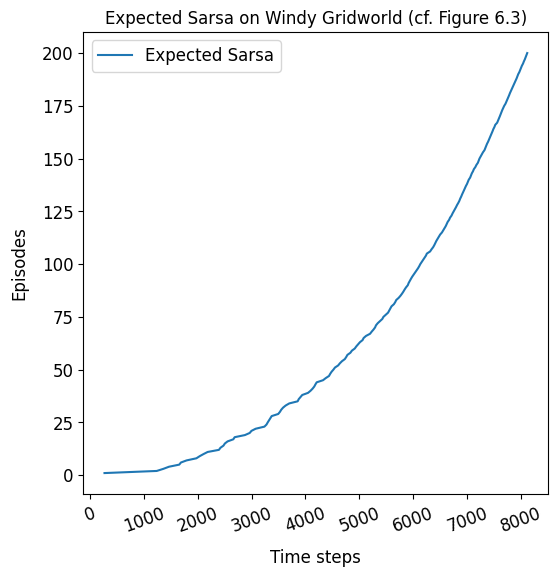

In [91]:
# Quick sanity check
np.random.seed(0)
expected_sarsa_agent = ExpectedSarsaAgent(alpha=0.5, epsilon=0.1)
expected_sarsa_steps = train(expected_sarsa_agent, num_episodes=200)

print("first 10 episodes:", expected_sarsa_steps[:10])
print("last 10 episodes: ", expected_sarsa_steps[-10:])

assert expected_sarsa_steps[-20:].mean() < expected_sarsa_steps[:20].mean()
assert expected_sarsa_steps[-20:].mean() < 30
print(f"mean steps over last 20 episodes: {expected_sarsa_steps[-20:].mean():.1f} (optimal is 15)")

plot_learning_curves({"Expected Sarsa": expected_sarsa_steps},
                      title="Expected Sarsa on Windy Gridworld (cf. Figure 6.3)")

## Q-learning

Off-policy TD control. The target bootstraps off the best available action-value at the next state, regardless of which action actually gets taken next -- its implicit target policy is greedy, even though `select_action` keeps exploring $\varepsilon$-greedily:

$$Q(S, A) \leftarrow Q(S, A) + \alpha \big[ R + \gamma \max_a Q(S', a) - Q(S, A) \big]$$

As with the others, if the episode ends on this step there's no $S'$ to bootstrap from, so the target is just $R$. `next_action` is accepted (to match the shared interface) but unused -- the target only needs `next_state`.

In [92]:
class QLearningAgent(TDAgent):
    USES_NEXT_ACTION = False

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))

    def select_action(self, state):
        row, col = state
        return epsilon_greedy(self.Q[row, col], self.epsilon)

    def update(self, state, action, reward, next_state, next_action, done):
        row, col = state
        current = self.Q[row, col, action]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            target = reward + self.gamma * self.Q[next_row, next_col].max()
        self.Q[row, col, action] = current + self.alpha * (target - current)

first 10 episodes: [251 830 260  79 299 100  77  79  41 139]
last 10 episodes:  [18 15 17 17 15 16 18 16 15 17]
mean steps over last 20 episodes: 17.3 (optimal is 15)


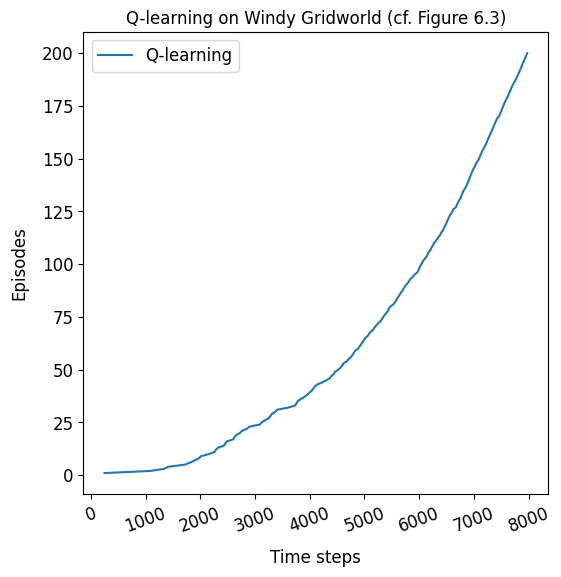

In [93]:
# Quick sanity check
np.random.seed(0)
q_learning_agent = QLearningAgent(alpha=0.5, epsilon=0.1)
q_learning_steps = train(q_learning_agent, num_episodes=200)

print("first 10 episodes:", q_learning_steps[:10])
print("last 10 episodes: ", q_learning_steps[-10:])

assert q_learning_steps[-20:].mean() < q_learning_steps[:20].mean()
assert q_learning_steps[-20:].mean() < 30
print(f"mean steps over last 20 episodes: {q_learning_steps[-20:].mean():.1f} (optimal is 15)")

plot_learning_curves({"Q-learning": q_learning_steps},
                      title="Q-learning on Windy Gridworld (cf. Figure 6.3)")

## Double Q-learning

Q-learning's `max` over a single, noisy `Q` table systematically overestimates action-values (the max of noisy estimates is itself a biased-high estimate of the max of the true values). Double Q-learning fixes this by keeping **two** independent tables, $Q_1$ and $Q_2$, and decorrelating "which action looks best" from "how good is that action" -- each update uses one table to pick the greedy action and the *other* table to evaluate it:

With probability 0.5 each step, either:

$$Q_1(S, A) \leftarrow Q_1(S, A) + \alpha \Big[ R + \gamma\, Q_2\big(S', \textstyle\arg\max_a Q_1(S', a)\big) - Q_1(S, A) \Big]$$

or the symmetric update with $Q_1$ and $Q_2$ swapped. Action selection (the behavior policy) is $\varepsilon$-greedy with respect to $Q_1 + Q_2$ -- the combined estimate is what the agent actually acts on, even though only one table gets updated on any given step.

In [94]:
class DoubleQLearningAgent(TDAgent):
    USES_NEXT_ACTION = False

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q1 = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))
        self.Q2 = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))

    def select_action(self, state):
        row, col = state
        return epsilon_greedy(self.Q1[row, col] + self.Q2[row, col], self.epsilon)

    def update(self, state, action, reward, next_state, next_action, done):
        row, col = state

        # Flip a coin: update Q1 using Q2 to evaluate Q1's greedy action, or
        # the symmetric update with the two tables swapped. Q_update and
        # Q_other are just names bound to the same underlying arrays as
        # self.Q1/self.Q2, so indexed assignment below still mutates
        # self.Q1 or self.Q2 directly.
        if np.random.rand() < 0.5:
            Q_update, Q_other = self.Q1, self.Q2
        else:
            Q_update, Q_other = self.Q2, self.Q1

        current = Q_update[row, col, action]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            greedy_action = np.argmax(Q_update[next_row, next_col])
            target = reward + self.gamma * Q_other[next_row, next_col, greedy_action]
        Q_update[row, col, action] = current + self.alpha * (target - current)

In [95]:
# Quick sanity check
np.random.seed(0)
double_q_agent = DoubleQLearningAgent(alpha=0.5, epsilon=0.1)
double_q_steps = train(double_q_agent, num_episodes=200)

print("first 10 episodes:", double_q_steps[:10])
print("last 10 episodes: ", double_q_steps[-10:])

assert double_q_steps[-20:].mean() < double_q_steps[:20].mean()
assert double_q_steps[-20:].mean() < 30
print(f"mean steps over last 20 episodes: {double_q_steps[-20:].mean():.1f} (optimal is 15)")

#plot_learning_curves({"Double Q-learning": double_q_steps},
#                      title="Double Q-learning on Windy Gridworld (cf. Figure 6.3)")

first 10 episodes: [968 273 722 599 183  90 150 121 114  80]
last 10 episodes:  [18 19 19 18 19 15 15 15 18 16]
mean steps over last 20 episodes: 17.1 (optimal is 15)


### Variant: swapping which table selects vs. evaluates

The canonical update above has the table being updated do the *selecting* (`argmax_a Q1`) and the other table do the *evaluating* (`Q2(...)`). The bias-removal argument only needs selector $\neq$ evaluator -- it doesn't obviously force *which* of the two plays which role. So here's the reversed pairing: the table being updated evaluates, the *other* table selects:

$$Q_1(S, A) \leftarrow Q_1(S, A) + \alpha \Big[ R + \gamma\, Q_1\big(S', \textstyle\arg\max_a Q_2(S', a)\big) - Q_1(S, A) \Big]$$

(and symmetrically for $Q_2$). $Q_1$ and $Q_2$ are symmetric a priori -- nothing distinguishes them before training starts beyond the coin flip -- so this should, by the same independence argument, also avoid the self-correlation bias. Implemented here to check that empirically against the canonical version.

In [96]:
class DoubleQLearningVariantAgent(TDAgent):
    """Same as DoubleQLearningAgent, except the roles are swapped: the
    table being updated supplies the VALUE, and the OTHER table does the
    action SELECTION (argmax) -- the reverse of the canonical pairing."""
    USES_NEXT_ACTION = False

    def __init__(self, alpha=0.5, epsilon=0.1, gamma=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma
        self.Q1 = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))
        self.Q2 = np.zeros((GRID_HEIGHT, GRID_WIDTH, len(ACTIONS)))

    def select_action(self, state):
        row, col = state
        return epsilon_greedy(self.Q1[row, col] + self.Q2[row, col], self.epsilon)

    def update(self, state, action, reward, next_state, next_action, done):
        row, col = state

        if np.random.rand() < 0.5:
            Q_update, Q_other = self.Q1, self.Q2
        else:
            Q_update, Q_other = self.Q2, self.Q1

        current = Q_update[row, col, action]
        if done:
            target = reward
        else:
            next_row, next_col = next_state
            # Swapped from the canonical version: the OTHER table selects...
            greedy_action = np.argmax(Q_other[next_row, next_col])
            # ...and the table being updated evaluates.
            target = reward + self.gamma * Q_update[next_row, next_col, greedy_action]
        Q_update[row, col, action] = current + self.alpha * (target - current)

first 10 episodes: [1207  446  544  220  148  395  209   33  120   59]
last 10 episodes:  [16 22 16 16 16 18 16 16 20 19]
mean steps over last 20 episodes: 17.4 (optimal is 15)


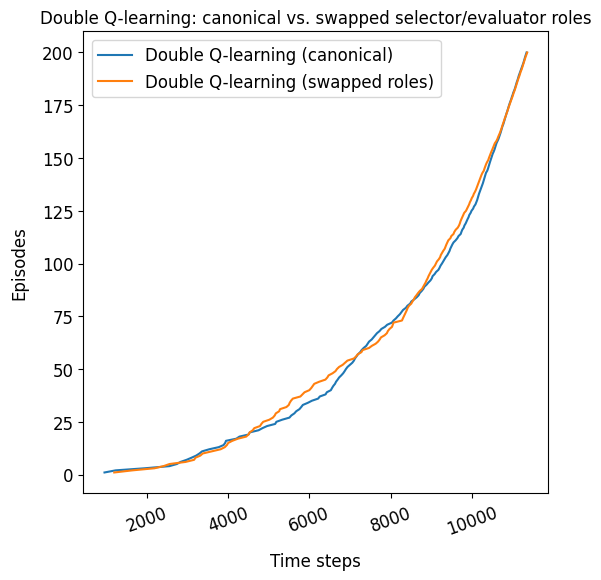

In [97]:
# Quick sanity check
np.random.seed(0)
double_q_variant_agent = DoubleQLearningVariantAgent(alpha=0.5, epsilon=0.1)
double_q_variant_steps = train(double_q_variant_agent, num_episodes=200)

print("first 10 episodes:", double_q_variant_steps[:10])
print("last 10 episodes: ", double_q_variant_steps[-10:])

assert double_q_variant_steps[-20:].mean() < double_q_variant_steps[:20].mean()
assert double_q_variant_steps[-20:].mean() < 30
print(f"mean steps over last 20 episodes: {double_q_variant_steps[-20:].mean():.1f} (optimal is 15)")

plot_learning_curves(
    {"Double Q-learning (canonical)": double_q_steps,
     "Double Q-learning (swapped roles)": double_q_variant_steps},
    title="Double Q-learning: canonical vs. swapped selector/evaluator roles",
)

### Comparison of four algorithms 

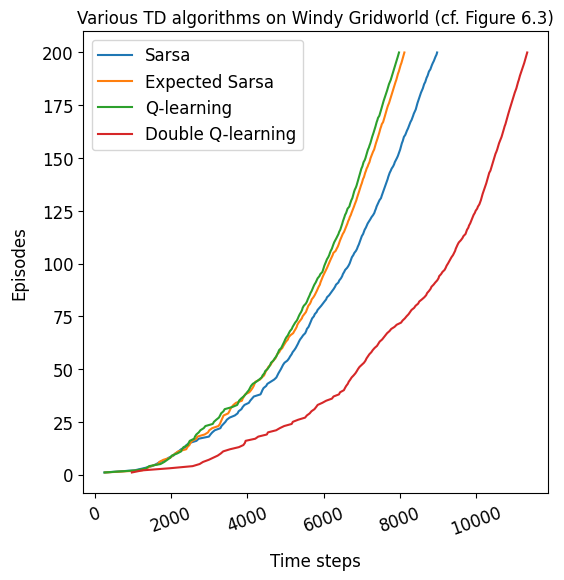

In [98]:
plot_learning_curves(
    {
        "Sarsa": sarsa_steps,
        "Expected Sarsa": expected_sarsa_steps,
        "Q-learning": q_learning_steps,
        "Double Q-learning": double_q_steps,
    },
    title="Various TD algorithms on Windy Gridworld (cf. Figure 6.3)"
)

## Discussion notes

A running summary of the conceptual questions worked through while building this notebook -- kept here for reference.

### Behavior policy vs. target policy

- **Behavior policy**: the policy that actually generates the agent's actions in the environment -- literally whatever `select_action` implements.
- **Target policy**: the policy whose value the TD target implicitly estimates -- i.e. whatever distribution underlies the bootstrap computation inside `update`. (`update` isn't literally a policy itself; the target it computes is only meaningful as "the expected value under *some* implicit policy," and that implicit policy is what we mean by the target policy.)
- When the two coincide, the algorithm is **on-policy**; when they differ, it's **off-policy**.

| Algorithm | `select_action` (behavior) | implicit policy inside `update` (target) | on/off-policy |
|---|---|---|---|
| Sarsa | $\varepsilon$-greedy w.r.t. $Q$ | $\varepsilon$-greedy w.r.t. $Q$ (the *same* `next_action` actually sampled) | on-policy |
| Expected Sarsa (as implemented here) | $\varepsilon$-greedy w.r.t. $Q$ | $\varepsilon$-greedy w.r.t. $Q$ (same $\varepsilon$, exact expectation) | on-policy |
| Q-learning | $\varepsilon$-greedy w.r.t. $Q$ | **greedy** w.r.t. $Q$ (via `max`) | off-policy |
| Double Q-learning | $\varepsilon$-greedy w.r.t. $Q_1+Q_2$ | **greedy** w.r.t. whichever table isn't being updated | off-policy |

Implementation note: `epsilon_greedy` breaks ties for the greedy action uniformly at random (via `np.flatnonzero(q_values == q_values.max())`) rather than always taking the first tied index -- otherwise the agent would develop a systematic bias toward low-index actions whenever several looked equally good (very common early in training, when most of `Q` is still all zeros).

### Expected Sarsa: same distribution, two different operations on it

A natural-seeming objection: `select_action` draws *one* sampled action, while `_expected_value` computes a weighted *sum* over all actions -- so are these really "the same policy"?

Resolution: on-policy-ness is about whether behavior and target use the **same probability distribution** $\pi(a\mid s)$, not about *how* that distribution gets consumed -- sampling from it vs. computing its exact expectation are two different numerical operations on the *same* $\pi$, not two different policies. With `q_values = [1, 3, 3, 2]`, $\varepsilon=0.1$: $\pi = [0.025, 0.475, 0.475, 0.025]$ (built via `np.full` for the baseline $\varepsilon/|A|$ share, then adding the $(1-\varepsilon)$ exploitation share onto the tied-greedy indices). `select_action` draws one sample from this $\pi$; `_expected_value` computes $\sum_a \pi(a) Q(s',a) = 2.925$ exactly. Sarsa's target (using one sampled action's $Q$-value) is literally a noisy, single-sample estimate of the exact same quantity Expected Sarsa computes in closed form -- same distribution, same quantity, just sampled vs. computed exactly. That's why both stay on-policy, as long as the *same* $\varepsilon$ is used in both places.

Contrast with what genuinely *would* make it off-policy: Q-learning is exactly "Expected Sarsa with the target's $\varepsilon$ forced to 0" -- all probability mass collapses onto the greedy action(s), giving $\max_a Q(s',a)$, while `select_action` still explores with $\varepsilon=0.1$. That's a real difference in *which distribution* is used for target vs. behavior -- hence off-policy.

### Q-learning's update rule, and why Q is treated as 0 when `done`

```python
if done:
    target = reward
else:
    target = reward + self.gamma * self.Q[next_row, next_col].max()
```

- This is **not** setting `Q(next_state, \cdot)` to zero -- it's choosing the TD target for `Q(state, action)`, the one entry actually being updated.
- The usual target is "what I got, plus an estimate of everything still to come." If `done` is True, `next_state` is the goal, and nothing happens after the goal -- so "everything still to come" is exactly 0 ($V(\text{terminal})=0$), and the target correctly collapses to just `reward`.
- It's also *necessary*, not just tidy: `run_episode` passes `next_action=None` whenever `done` is True (no action is ever chosen from the goal), so without this branch, indexing with `None` would crash.
- The goal cell's row in `Q` is never read or written at all, since `select_action` is never called from the goal -- it just sits at its initial `0.0`, which happens to be the right value anyway.

### Double Q-learning's update rule: can $Q_1$ and $Q_2$ be swapped?

- The canonical update has the table being updated do the *selecting* and the *other* table do the *evaluating*:

$$Q_1(S,A) \leftarrow Q_1(S,A) + \alpha\big[R + \gamma\, Q_2(S', \arg\max_a Q_1(S',a)) - Q_1(S,A)\big]$$

(symmetrically for $Q_2$) -- matching the published algorithm (van Hasselt; Sutton & Barto Section 6.7).

- *Why two tables remove the bias at all*: ordinary (single-table) Q-learning's `max` both picks the best-looking action *and* supplies its value from the *same* noisy table -- whichever action happened to get a lucky positive noise fluctuation is exactly the one `argmax` picks, and then that same inflated number gets read right back out as the target. The fix only requires selector $\neq$ evaluator: using two independently-noisy tables, whichever one didn't do the selecting isn't correlated with *why* that action got picked, so its evaluation stays honest.

- *The question raised*: does it matter *which* of the two tables plays which role, given that we're updating $Q_1$ specifically? I.e. could the *other* table ($Q_2$) do the selecting, while $Q_1$ (the one being updated) does the evaluating -- the reverse of the canonical pairing?

- The bias-removal argument above only needs selector $\neq$ evaluator -- it doesn't obviously force a *specific* assignment of roles relative to which table happens to be the one being updated. $Q_1$ and $Q_2$ are symmetric *a priori* (nothing distinguishes them before training starts, beyond the coin flip deciding which one updates on a given step), so swapping the roles should, by the same independence argument, also avoid the self-correlation bias.

- Implemented as `DoubleQLearningVariantAgent` to check this empirically: the canonical pairing converged to a mean of ~17.1 steps over the last 20 episodes; the swapped-role variant converged to ~17.8 -- indistinguishable at this scale, consistent with the theoretical expectation that either pairing works as long as selector and evaluator are different tables. The textbook's specific pairing is a matter of fidelity to the published algorithm, not a claim that the reverse is mathematically wrong.

### Action selection at inference (deployment) time

- During training we act $\varepsilon$-greedily, to keep exploring. Once the policy is no longer being improved, the right choice is to act purely **greedily**: $a=\arg\max_a Q(s,a)$, ties broken randomly as during training.
- `epsilon_greedy(q_values, epsilon=0.0)` already *is* exactly this -- `np.random.rand() < 0.0` is always `False`, so it always falls through to the exploit branch. No new code needed.
- Subtlety: *which* `Q` you deploy matters. Q-learning/Double Q-learning's target policy during training was already greedy, so their learned `Q` already approximates the value under the greedy policy -- deploying greedily matches what was actually learned. Sarsa/Expected Sarsa (on-policy here) converge to the value of behaving $\varepsilon$-greedily *forever*, including the cost of their own occasional exploratory mistakes -- so deploying greedily off an on-policy-learned `Q` runs a genuinely different policy than the one whose value was estimated. (This is the same phenomenon behind the book's Cliff Walking example: Sarsa learns a safer path because its on-policy value estimates account for the real risk of an $\varepsilon$-greedy slip; Q-learning learns the objectively shortest but riskier path.)

### Comparing the four algorithms

- The Figure-6.3-style plot (cumulative time steps vs. episodes completed) is dominated by the first several episodes, since those are by far the longest and most variable.
- In our run, Double Q-learning's first 10 episodes totaled ~3,300 steps vs. ~2,100-2,150 for the other three -- a real, expected property: on any given step only *one* of its two tables gets updated (coin flip), so each table individually learns at roughly half the effective rate early on. That slow start pushes its whole curve to the right on this plot, which reads visually as "performing worst" -- even though that's really "took longer to get through the first several episodes," not "learned a worse policy."
- Looking instead at **asymptotic** performance (mean steps over the last 20 episodes, already printed by each algorithm's own sanity check): Expected Sarsa (16.8), Q-learning (17.3), and Double Q-learning (17.1) are all within half a step of each other -- essentially tied. **Sarsa is actually the worst by this measure (21.9)** -- the opposite of what the cumulative plot visually emphasizes -- because, being on-policy, it converges to the value of continuing to explore $\varepsilon$-greedily forever, a genuinely worse target here than the near-greedy policies the other three converge toward.
- Takeaway: "which algorithm is best" depends on *what's being measured* -- cost of the learning process itself (where the cumulative plot is informative) vs. quality of the final learned policy (where the last-$N$-episode mean is the cleaner comparison) give different answers, and conflating them is easy to do by eye.

### On hyperparameters ($\gamma$, $\alpha$, $\varepsilon$)

- $\gamma$ isn't really a free hyperparameter here -- it's fixed by the problem's own definition (undiscounted, episodic), not something to search over.
- $\alpha$ and $\varepsilon$ genuinely trade off: $\alpha$ controls how fast estimates adapt vs. how noisy/unstable they stay (a *fixed* $\alpha$, as used throughout, never fully converges -- it trades a small persistent bias for staying responsive; a *decaying* $\alpha$ converges more precisely but learns slower early on). $\varepsilon$ controls exploration vs. exploitation, and for on-policy methods it directly affects the *quality of the converged policy itself*, not just how fast you get there.
- Practical approach for a problem this small and cheap to simulate: a full grid search over a handful of $(\alpha, \varepsilon)$ values, averaged over many random seeds (not just one -- a single seed's early-episode lengths vary a lot, as seen above), choosing a metric that matches what actually matters -- asymptotic quality (last-$N$-episode mean) vs. learning efficiency / cumulative cost (total steps or reward over the *whole* training run) can give different answers and should be chosen deliberately. No need for anything fancier than exhaustive grid search at this scale (e.g. Bayesian optimization would be overkill for a search this cheap).